# Lightweight Models

Compare efficient model architectures.

In [41]:
import torch
import torch.nn as nn
from torchvision import models

device=torch.device('cuda' if torch.cuda.is_available() else "cpu")
print("Using device:", device)


Using device: cuda


In [42]:

import sys
import torch

print("Python executable:", sys.executable)
print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("CUDA version:", torch.version.cuda)

Python executable: c:\Users\DARPAN\AppData\Local\Python\pythoncore-3.14-64\python.exe
PyTorch version: 2.10.0+cu128
CUDA available: True
CUDA version: 12.8


In [43]:
from pathlib import Path
import pandas as pd
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image

# Project paths
project_root = Path.cwd().parent
metadata_dir = project_root / "data" / "metadata"
image_dir = project_root / "data" / "raw" / "images"

# Select GPU if available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# Check paths
print("Images folder exists:", image_dir.exists())
print("Training CSV exists:", (metadata_dir / "train_split.csv").exists())

train_df = pd.read_csv(metadata_dir / "train_split.csv")
val_df = pd.read_csv(metadata_dir / "val_split.csv")
test_df = pd.read_csv(metadata_dir / "test_split.csv")

print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Test images:", len(test_df))

print("Columns:", train_df.columns.tolist())

Device: cuda
Images folder exists: True
Training CSV exists: True
Training images: 1740
Validation images: 435
Test images: 977
Columns: ['Image Name', 'Majority Vote Label', 'Number of Annotators who Selected SSA (Out of 7)', 'Partition']


In [44]:
print("train_loader defined:", "train_loader" in globals())
print("Images folder:", image_dir.exists())
print("Training rows:", len(train_df))

print("First filename:", train_df.iloc[0]["Image Name"])
print("First label:", train_df.iloc[0]["Majority Vote Label"])

train_loader defined: True
Images folder: True
Training rows: 1740
First filename: MHIST_edl.png
First label: SSA


In [45]:
image_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])
from pathlib import Path

missing_name = "MHIST_dlf.png"

print("Expected path:", image_dir / missing_name)
print("File exists:", (image_dir / missing_name).exists())

# Search all extracted image subfolders
matches = list(image_dir.rglob(missing_name))
print("Matches found:", matches)

available_names = {p.name for p in image_dir.rglob("*.png")}

for df_name, df in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    missing = set(df["Image Name"]) - available_names
    print(f"{df_name}: {len(missing)} missing images")
    print("Examples:", list(missing)[:10])
class MHISTDataset(Dataset):
    def __init__(self, dataframe, image_dir, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.image_dir = Path(image_dir)
        self.transform = transform
        self.label_map = {"HP": 0, "SSA": 1}

        self.image_paths = {
            p.name: p for p in self.image_dir.rglob("*.png")
        }

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):
        row = self.dataframe.iloc[idx]
        filename = row["Image Name"]

        if filename not in self.image_paths:
            raise FileNotFoundError(
                f"Image not found: {filename}"
            )

        image = Image.open(self.image_paths[filename]).convert("RGB")
        label = self.label_map[row["Majority Vote Label"]]

        if self.transform:
            image = self.transform(image)

        return image, torch.tensor(label, dtype=torch.long)

train_dataset = MHISTDataset(
    train_df, image_dir, image_transform
)

val_dataset = MHISTDataset(
    val_df, image_dir, image_transform
)

test_dataset = MHISTDataset(
    test_df, image_dir, image_transform
)

train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0
)

print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Labels in batch:", labels.unique().tolist())
print("Device:", device)

Expected path: c:\Users\DARPAN\Deep-learning-PBL-3\MHIST-Research\data\raw\images\MHIST_dlf.png
File exists: False
Matches found: [WindowsPath('c:/Users/DARPAN/Deep-learning-PBL-3/MHIST-Research/data/raw/images/images/MHIST_dlf.png')]
Train: 0 missing images
Examples: []
Validation: 0 missing images
Examples: []
Test: 0 missing images
Examples: []
Train batches: 55
Validation batches: 14
Test batches: 31
Image batch shape: torch.Size([32, 3, 224, 224])
Label batch shape: torch.Size([32])
Labels in batch: [0, 1]
Device: cuda


In [46]:
model=models.mobilenet_v3_small(weights="DEFAULT")
print(model.classifier)

Sequential(
  (0): Linear(in_features=576, out_features=1024, bias=True)
  (1): Hardswish()
  (2): Dropout(p=0.2, inplace=True)
  (3): Linear(in_features=1024, out_features=1000, bias=True)
)


In [47]:
num_features=model.classifier[-1].in_features
model.classifier[-1]=nn.Linear(num_features,2)
model=model.to(device)
print(model)

MobileNetV3(
  (features): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(16, eps=0.001, momentum=0.01, affine=True, track_running_stats=True)
      (2): Hardswish()
    )
    (1): InvertedResidual(
      (block): Sequential(
        (0): Conv2dNormActivation(
          (0): Conv2d(16, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), groups=16, bias=False)
          (1): BatchNorm2d(16, eps=0.001, momentum=0.01, affine=True, track_running_stats=True)
          (2): ReLU(inplace=True)
        )
        (1): SqueezeExcitation(
          (avgpool): AdaptiveAvgPool2d(output_size=1)
          (fc1): Conv2d(16, 8, kernel_size=(1, 1), stride=(1, 1))
          (fc2): Conv2d(8, 16, kernel_size=(1, 1), stride=(1, 1))
          (activation): ReLU()
          (scale_activation): Hardsigmoid()
        )
        (2): Conv2dNormActivation(
          (0): Conv2d(16, 16, kernel_size=(1, 1), 

In [48]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.0001)
num_epochs = 5

train_losses = []
val_losses = []
train_accuracies = []
val_accuracies = []

for epoch in range(num_epochs):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * labels.size(0)
        correct += (outputs.argmax(dim=1) == labels).sum().item()
        total += labels.size(0)

    train_losses.append(running_loss / total)
    train_accuracies.append(correct / total)

    model.eval()
    val_running_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_running_loss += loss.item() * labels.size(0)
            val_correct += (outputs.argmax(dim=1) == labels).sum().item()
            val_total += labels.size(0)

    val_losses.append(val_running_loss / val_total)
    val_accuracies.append(val_correct / val_total)

    print(
        f"Epoch [{epoch + 1}/{num_epochs}] "
        f"Train Loss: {train_losses[-1]:.4f}, "
        f"Train Accuracy: {train_accuracies[-1]:.4f}, "
        f"Validation Loss: {val_losses[-1]:.4f}, "
        f"Validation Accuracy: {val_accuracies[-1]:.4f}"
    )


Epoch [1/5] Train Loss: 0.5114, Train Accuracy: 0.7552, Validation Loss: 0.5335, Validation Accuracy: 0.7149
Epoch [2/5] Train Loss: 0.3469, Train Accuracy: 0.8523, Validation Loss: 0.4508, Validation Accuracy: 0.7931
Epoch [3/5] Train Loss: 0.2489, Train Accuracy: 0.8977, Validation Loss: 0.3761, Validation Accuracy: 0.8621
Epoch [4/5] Train Loss: 0.1633, Train Accuracy: 0.9402, Validation Loss: 0.3529, Validation Accuracy: 0.8621
Epoch [5/5] Train Loss: 0.1186, Train Accuracy: 0.9569, Validation Loss: 0.3154, Validation Accuracy: 0.8736


In [49]:
from pathlib import Path
import torch

# Create the folder for model checkpoints
checkpoint_dir = project_root / "models" / "checkpoints"
checkpoint_dir.mkdir(parents=True, exist_ok=True)

# Save the trained model parameters
model_path = checkpoint_dir / "mobilenet_v3_small.pth"
torch.save(model.state_dict(), model_path)

print("Model saved to:", model_path)

Model saved to: c:\Users\DARPAN\Deep-learning-PBL-3\MHIST-Research\models\checkpoints\mobilenet_v3_small.pth


Actual test samples: 977
Evaluated samples: 977
Actual class counts: Counter({np.int64(0): 617, np.int64(1): 360})
Predicted class counts: Counter({np.int64(0): 680, np.int64(1): 297})

Accuracy: 0.8229273285568065
Precision: 0.8148148148148148
Recall: 0.6722222222222223
F1-score: 0.7366818873668188
ROC-AUC: 0.9049117594093283

Classification Report:
              precision    recall  f1-score   support

          HP       0.83      0.91      0.87       617
         SSA       0.81      0.67      0.74       360

    accuracy                           0.82       977
   macro avg       0.82      0.79      0.80       977
weighted avg       0.82      0.82      0.82       977



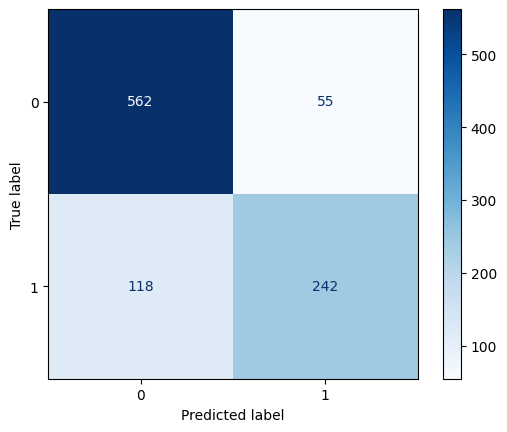

In [50]:


from collections import Counter
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report, confusion_matrix,ConfusionMatrixDisplay
)
import torch
import matplotlib.pyplot as plt
model.eval()

all_labels = []
all_predictions = []
all_probabilities = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)

        # Predicted class for each image
        predictions = outputs.argmax(dim=1)

        # Probability of class 1 (SSA, assuming label 1 = SSA)
        probabilities = torch.softmax(outputs, dim=1)[:, 1]

        all_labels.extend(labels.cpu().numpy())
        all_predictions.extend(predictions.cpu().numpy())
        all_probabilities.extend(probabilities.cpu().numpy())

# Print counts AFTER the loop
print("Actual test samples:", len(test_dataset))
print("Evaluated samples:", len(all_labels))
print("Actual class counts:", Counter(all_labels))
print("Predicted class counts:", Counter(all_predictions))

# Calculate metrics
print("\nAccuracy:", accuracy_score(all_labels, all_predictions))
print("Precision:", precision_score(
    all_labels, all_predictions, zero_division=0
))
print("Recall:", recall_score(
    all_labels, all_predictions, zero_division=0
))
print("F1-score:", f1_score(
    all_labels, all_predictions, zero_division=0
))

if len(set(all_labels)) == 2:
    print("ROC-AUC:", roc_auc_score(all_labels, all_probabilities))
else:
    print("ROC-AUC cannot be calculated: only one actual class.")

print("\nClassification Report:")
print(classification_report(
    all_labels,
    all_predictions,
    labels=[0, 1],
    target_names=["HP", "SSA"],
    zero_division=0
))
cm=confusion_matrix(all_labels,all_predictions,labels=[0,1])
disp=ConfusionMatrixDisplay(cm)
disp.plot(cmap=plt.cm.Blues)
plt.show()

mobilenet_results = {
    "Model": "MobileNetV3-Small",
    "Accuracy": accuracy_score(all_labels, all_predictions),
    "Precision": precision_score(all_labels, all_predictions, zero_division=0),
    "Recall": recall_score(all_labels, all_predictions, zero_division=0),
    "F1 Score": f1_score(all_labels, all_predictions, zero_division=0),
    "ROC-AUC": roc_auc_score(all_labels, all_probabilities) if len(set(all_labels)) == 2 else None
}


In [51]:
import pandas as pd
from pathlib import Path

metadata_dir = project_root / "data" / "metadata"

for name in ["train_split.csv", "val_split.csv", "test_split.csv"]:
    df = pd.read_csv(metadata_dir / name)

    print(f"\n{name}")
    print("Rows:", len(df))
    print("Class counts:")
    print(df["Majority Vote Label"].value_counts())
    print("Partitions:")
    print(df["Partition"].value_counts())


train_split.csv
Rows: 1740
Class counts:
Majority Vote Label
HP     1236
SSA     504
Name: count, dtype: int64
Partitions:
Partition
train    1740
Name: count, dtype: int64

val_split.csv
Rows: 435
Class counts:
Majority Vote Label
HP     309
SSA    126
Name: count, dtype: int64
Partitions:
Partition
train    435
Name: count, dtype: int64

test_split.csv
Rows: 977
Class counts:
Majority Vote Label
HP     617
SSA    360
Name: count, dtype: int64
Partitions:
Partition
test    977
Name: count, dtype: int64


In [52]:
print("Train dataset:", len(train_dataset))
print("Validation dataset:", len(val_dataset))
print("Test dataset:", len(test_dataset))

print("\nTest labels:")
print(test_df["Majority Vote Label"].value_counts())

print("\nLabels in test dataset:")
from collections import Counter

print(Counter(
    test_dataset[i][1].item()
    for i in range(len(test_dataset))
))

Train dataset: 1740
Validation dataset: 435
Test dataset: 977

Test labels:
Majority Vote Label
HP     617
SSA    360
Name: count, dtype: int64

Labels in test dataset:
Counter({0: 617, 1: 360})


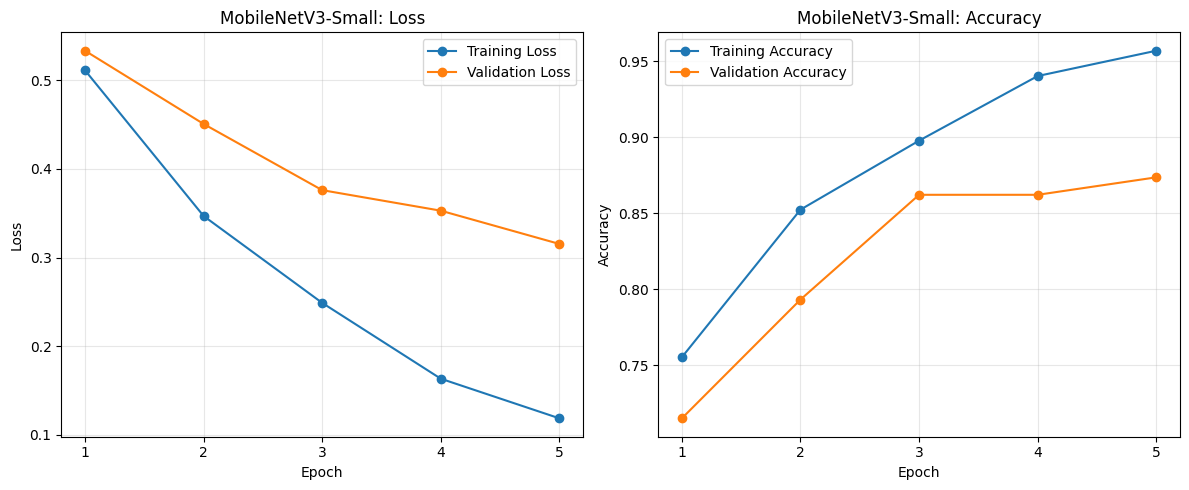

In [53]:
epochs = range(1, len(train_losses) + 1)

plt.figure(figsize=(12, 5))

# Loss curves
plt.subplot(1, 2, 1)
plt.plot(epochs, train_losses, marker="o", label="Training Loss")
plt.plot(epochs, val_losses, marker="o", label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("MobileNetV3-Small: Loss")
plt.xticks(list(epochs))
plt.legend()
plt.grid(True, alpha=0.3)

# Accuracy curves
plt.subplot(1, 2, 2)
plt.plot(epochs, train_accuracies, marker="o", label="Training Accuracy")
plt.plot(epochs, val_accuracies, marker="o", label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("MobileNetV3-Small: Accuracy")
plt.xticks(list(epochs))
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [54]:
import torch
import torch.nn as nn
from torchvision import models

device=torch.device('cuda' if torch.cuda.is_available() else "cpu")
shufflenet= models.shufflenet_v2_x0_5(weights=models.ShuffleNet_V2_X0_5_Weights.DEFAULT)
num_features=shufflenet.fc.in_features
shufflenet.fc=nn.Linear(num_features,2)

shufflenet=shufflenet.to(device)
print("Model: ShuffleNetV2 x0.5")
print("Device:", device)
print("Output classes:", shufflenet.fc.out_features)

Model: ShuffleNetV2 x0.5
Device: cuda
Output classes: 2


In [55]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(shufflenet.parameters(), lr=0.0001)
num_epochs = 5

train_losses = []
val_losses = []
train_accuracies = []
val_accuracies = []

for epoch in range(num_epochs):
    shufflenet.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        outputs = shufflenet(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * labels.size(0)
        correct += (outputs.argmax(dim=1) == labels).sum().item()
        total += labels.size(0)

    train_losses.append(running_loss / total)
    train_accuracies.append(correct / total)

    shufflenet.eval()
    val_running_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = shufflenet(images)
            loss = criterion(outputs, labels)

            val_running_loss += loss.item() * labels.size(0)
            val_correct += (outputs.argmax(dim=1) == labels).sum().item()
            val_total += labels.size(0)

    val_losses.append(val_running_loss / val_total)
    val_accuracies.append(val_correct / val_total)

    print(
        f"Epoch [{epoch + 1}/{num_epochs}] "
        f"Train Loss: {train_losses[-1]:.4f}, "
        f"Train Accuracy: {train_accuracies[-1]:.4f}, "
        f"Validation Loss: {val_losses[-1]:.4f}, "
        f"Validation Accuracy: {val_accuracies[-1]:.4f}"
    )


Epoch [1/5] Train Loss: 0.6709, Train Accuracy: 0.6626, Validation Loss: 0.6308, Validation Accuracy: 0.7103
Epoch [2/5] Train Loss: 0.5887, Train Accuracy: 0.7109, Validation Loss: 0.5126, Validation Accuracy: 0.7103
Epoch [3/5] Train Loss: 0.5060, Train Accuracy: 0.7149, Validation Loss: 0.4701, Validation Accuracy: 0.7149
Epoch [4/5] Train Loss: 0.4501, Train Accuracy: 0.7190, Validation Loss: 0.4268, Validation Accuracy: 0.7287
Epoch [5/5] Train Loss: 0.4050, Train Accuracy: 0.7529, Validation Loss: 0.3957, Validation Accuracy: 0.7908


In [56]:
from pathlib import Path
import torch

# Create the folder for model checkpoints
checkpoint_dir = project_root / "models" / "checkpoints"
checkpoint_dir.mkdir(parents=True, exist_ok=True)

# Save the trained model parameters
model_path = checkpoint_dir / "shufflenet_v3_small.pth"
torch.save(shufflenet.state_dict(), model_path)

print("Model saved to:", model_path)

Model saved to: c:\Users\DARPAN\Deep-learning-PBL-3\MHIST-Research\models\checkpoints\shufflenet_v3_small.pth


Actual test samples: 977
Evaluated samples: 977
Actual class counts: Counter({np.int64(0): 617, np.int64(1): 360})
Predicted class counts: Counter({np.int64(0): 864, np.int64(1): 113})

Accuracy: 0.7021494370522006
Precision: 0.8053097345132744
Recall: 0.25277777777777777
F1-score: 0.38477801268498946
ROC-AUC: 0.8345128759229246

Classification Report:
              precision    recall  f1-score   support

          HP       0.69      0.96      0.80       617
         SSA       0.81      0.25      0.38       360

    accuracy                           0.70       977
   macro avg       0.75      0.61      0.59       977
weighted avg       0.73      0.70      0.65       977



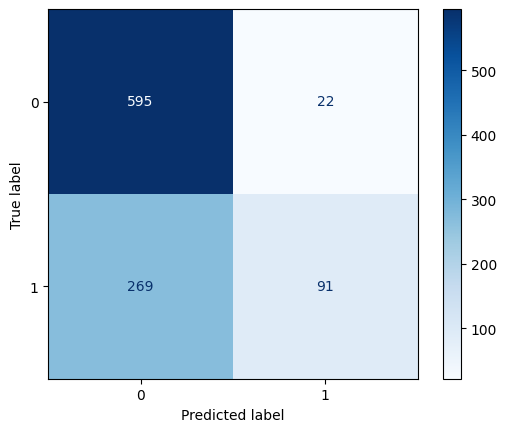

In [57]:
from collections import Counter
from sklearn.metrics import (accuracy_score,precision_score,recall_score,f1_score, roc_auc_score,classification_report, confusion_matrix,ConfusionMatrixDisplay)
import torch
import matplotlib.pyplot as plt
shufflenet.eval()

all_labels = []
all_predictions = []
all_probabilities = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = shufflenet(images)

        # Predicted class for each image
        predictions = outputs.argmax(dim=1)

        # Probability of class 1 (SSA, assuming label 1 = SSA)
        probabilities = torch.softmax(outputs, dim=1)[:, 1]

        all_labels.extend(labels.cpu().numpy())
        all_predictions.extend(predictions.cpu().numpy())
        all_probabilities.extend(probabilities.cpu().numpy())

# Print counts AFTER the loop
print("Actual test samples:", len(test_dataset))
print("Evaluated samples:", len(all_labels))
print("Actual class counts:", Counter(all_labels))
print("Predicted class counts:", Counter(all_predictions))

# Calculate metrics
print("\nAccuracy:", accuracy_score(all_labels, all_predictions))
print("Precision:", precision_score(
    all_labels, all_predictions, zero_division=0
))
print("Recall:", recall_score(
    all_labels, all_predictions, zero_division=0
))
print("F1-score:", f1_score(
    all_labels, all_predictions, zero_division=0
))

if len(set(all_labels)) == 2:
    print("ROC-AUC:", roc_auc_score(all_labels, all_probabilities))
else:
    print("ROC-AUC cannot be calculated: only one actual class.")

print("\nClassification Report:")
print(classification_report(
    all_labels,
    all_predictions,
    labels=[0, 1],
    target_names=["HP", "SSA"],
    zero_division=0
))
cm=confusion_matrix(all_labels,all_predictions,labels=[0,1])
disp=ConfusionMatrixDisplay(cm)
disp.plot(cmap=plt.cm.Blues)
plt.show()

shufflenet_results = {
    "Model": "ShuffleNetV2 x0.5",
    "Accuracy": accuracy_score(all_labels, all_predictions),
    "Precision": precision_score(all_labels, all_predictions, zero_division=0),
    "Recall": recall_score(all_labels, all_predictions, zero_division=0),
    "F1 Score": f1_score(all_labels, all_predictions, zero_division=0),
    "ROC-AUC": roc_auc_score(all_labels, all_probabilities) if len(set(all_labels)) == 2 else None
}


In [58]:
print("Train dataset:", len(train_dataset))
print("Validation dataset:", len(val_dataset))
print("Test dataset:", len(test_dataset))

print("\nTest labels:")
print(test_df["Majority Vote Label"].value_counts())

print("\nLabels in test dataset:")
from collections import Counter

print(Counter(
    test_dataset[i][1].item()
    for i in range(len(test_dataset))
))

Train dataset: 1740
Validation dataset: 435
Test dataset: 977

Test labels:
Majority Vote Label
HP     617
SSA    360
Name: count, dtype: int64

Labels in test dataset:
Counter({0: 617, 1: 360})


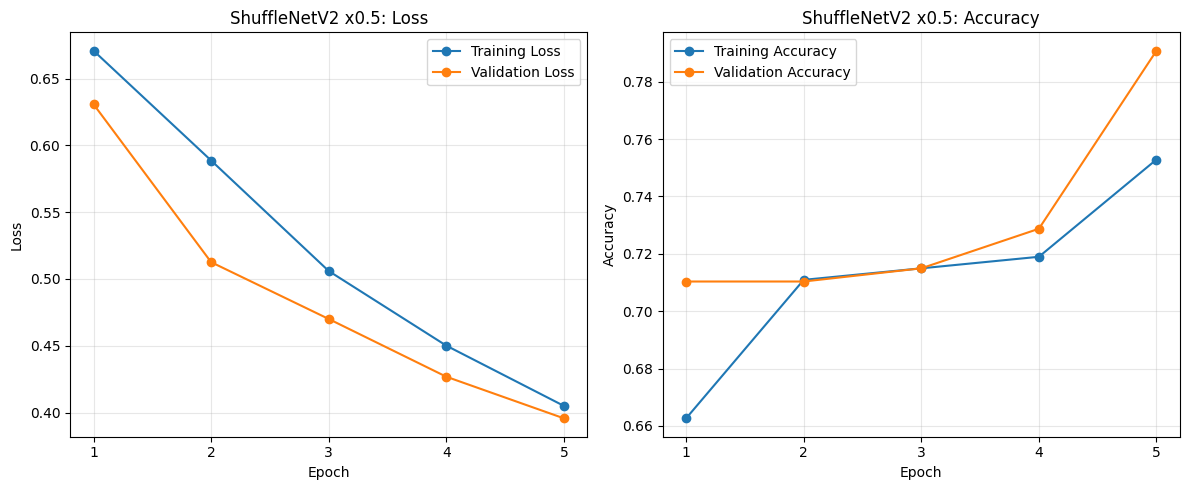

In [59]:
epochs = range(1, len(train_losses) + 1)

plt.figure(figsize=(12, 5))

# Loss curves
plt.subplot(1, 2, 1)
plt.plot(epochs, train_losses, marker="o", label="Training Loss")
plt.plot(epochs, val_losses, marker="o", label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("ShuffleNetV2 x0.5: Loss")
plt.xticks(list(epochs))
plt.legend()
plt.grid(True, alpha=0.3)

# Accuracy curves
plt.subplot(1, 2, 2)
plt.plot(epochs, train_accuracies, marker="o", label="Training Accuracy")
plt.plot(epochs, val_accuracies, marker="o", label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("ShuffleNetV2 x0.5: Accuracy")
plt.xticks(list(epochs))
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

Final Test-Set Model Comparison


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,ResNet18,79.22,66.12,89.44,76.03,89.49
1,EfficientNet-B0,85.06,77.16,84.44,80.64,92.30
2,MobileNetV3-Small,82.29,81.48,67.22,73.67,90.49
3,ShuffleNetV2 x0.5,70.21,80.53,25.28,38.48,83.45


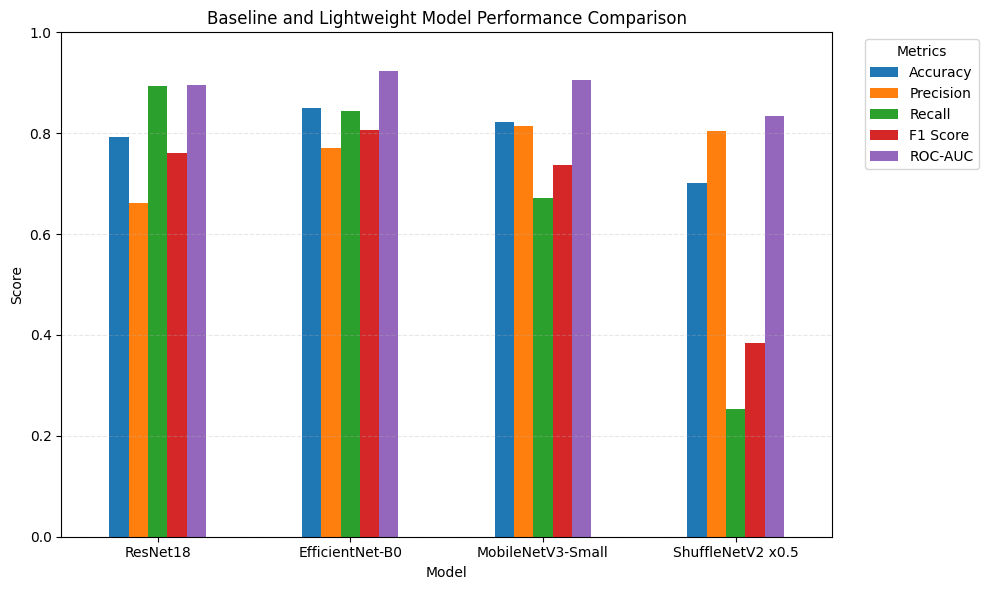

In [60]:
# Results from the two baseline models
resnet18_results = {
    "Model": "ResNet18",
    "Accuracy": 0.7922,
    "Precision": 0.6612,
    "Recall": 0.8944,
    "F1 Score": 0.7603,
    "ROC-AUC": 0.8949
}

efficientnet_results = {
    "Model": "EfficientNet-B0",
    "Accuracy": 0.8506,
    "Precision": 0.7716,
    "Recall": 0.8444,
    "F1 Score": 0.8064,
    "ROC-AUC": 0.9230
}

# Combine the results
comparison_df = pd.DataFrame([
    resnet18_results,
    efficientnet_results,
    mobilenet_results,
    shufflenet_results
])

# Display percentages
comparison_display = comparison_df.copy()

metric_columns = [
    "Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC"
]

comparison_display[metric_columns] = (
    comparison_display[metric_columns] * 100
).round(2)

print("Final Test-Set Model Comparison")
display(comparison_display)

comparison_df.set_index("Model").plot( kind="bar",figsize=(10, 6))

plt.title("Baseline and Lightweight Model Performance Comparison")
plt.xlabel("Model")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(title="Metrics", loc="upper right", bbox_to_anchor=(1.2, 1))
plt.grid(axis="y", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

In [61]:
def count_parameters(model):
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return total, trainable


def get_model_size_mb(model):
    # Approximate size of the model weights in memory
    size_bytes = sum(p.numel() * p.element_size() for p in model.parameters())
    return size_bytes / (1024 ** 2)


# Load the baseline architectures for comparison
resnet_model = models.resnet18(weights=None)
resnet_model.fc = nn.Linear(resnet_model.fc.in_features, 2)

efficientnet_model = models.efficientnet_b0(weights=None)
efficientnet_model.classifier[1] = nn.Linear(efficientnet_model.classifier[1].in_features, 2)

models_to_compare = {
    "ResNet18": resnet_model,
    "EfficientNet-B0": efficientnet_model,
    "MobileNetV3-Small": model,
    "ShuffleNetV2 x0.5": shufflenet
}

efficiency_rows = []

for name, model in models_to_compare.items():
    total_params, trainable_params = count_parameters(model)

    efficiency_rows.append({
        "Model": name,
        "Total Parameters (M)": round(total_params / 1e6, 3),
        "Trainable Parameters (M)": round(trainable_params / 1e6, 3),
        "Weight Size (MB)": round(get_model_size_mb(model), 2)
    })

efficiency_df = pd.DataFrame(efficiency_rows)

print("Model Efficiency Comparison")
display(efficiency_df)

Model Efficiency Comparison


,Model,Total Parameters (M),Trainable Parameters (M),Weight Size (MB)
0,ResNet18,11.178,11.178,42.64
1,EfficientNet-B0,4.010,4.010,15.30
2,MobileNetV3-Small,1.520,1.520,5.80
3,ShuffleNetV2 x0.5,0.344,0.344,1.31


In [62]:
import time

def measure_inference_time(model, device, input_shape=(1, 3, 224, 224), runs=50):
    model = model.to(device)
    model.eval()

    dummy_input = torch.randn(*input_shape).to(device)

    # Warm-up
    with torch.no_grad():
        for _ in range(5):
            _ = model(dummy_input)

    # Measure inference time
    start = time.perf_counter()

    with torch.no_grad():
        for _ in range(runs):
            _ = model(dummy_input)

    elapsed = time.perf_counter() - start

    return (elapsed / runs) * 1000  # milliseconds per image


# Measure all three models
inference_rows = []

for name, model in models_to_compare.items():
    model = model.to(device)
    latency_ms = measure_inference_time(model, device)

    inference_rows.append({
        "Model": name,
        "Inference Time (ms/image)": round(latency_ms, 2)
    })

inference_df = pd.DataFrame(inference_rows)

print("Inference Speed Comparison (single image)")
display(inference_df)

Inference Speed Comparison (single image)


,Model,Inference Time (ms/image)
0,ResNet18,7.95
1,EfficientNet-B0,10.47
2,MobileNetV3-Small,6.80
3,ShuffleNetV2 x0.5,7.81


In [63]:
# Create results folder if it doesn't exist
import os
os.makedirs("../results", exist_ok=True)

# Save test metrics
comparison_df.to_csv("../results/model_comparison.csv",index=False)

# Save parameter counts and model sizes
efficiency_df.to_csv("../results/model_efficiency.csv",index=False)

# Save inference timings
inference_df.to_csv("../results/inference_speed.csv",index=False)

print("Saved files:")
print("../results/model_comparison.csv")
print("../results/model_efficiency.csv")
print("../results/inference_speed.csv")

Saved files:
../results/model_comparison.csv
../results/model_efficiency.csv
../results/inference_speed.csv
